# Pretrained Transfer Learning with Source Pretraining, Target Fine-Tuning, and Layer-wise PC Tracking

## Task Description
Implementation of a two-stage transfer learning pipeline based on Di et al. (2025):
1. **Target Fixed Subsets Setup**:
   - At initialization, draw and fix `SAMPLE_SIZES` instances from the target dataset `NUM_REPLICATIONS` times with fixed random seeds for reproducible target validation loss and layer-wise Projection Correlation (PC) evaluation with confidence intervals.
2. **Stage 1 — Source Pretraining with Early Stopping & Control**:
   - Pretrain a 6-layer CNN on the source dataset with early stopping monitored on source validation loss.
   - Upon triggering early stopping, continue training for an additional control period defined by the named constant `POST_EARLY_STOP_EPOCHS = 10`.
   - Log each epoch: Train Loss, Source Validation Loss, Source Test Accuracy, Target Validation Loss, and PC for all layers across replications.
   - Plot loss/accuracy curves and PC layer trajectories.
   - Save the pretrained model checkpoint and metrics to `pretrained/` with timestamps.
3. **Stage 2 — Target Fine-Tuning with Early Stopping**:
   - Fine-tune the model on the fixed `SAMPLE_SIZES` target subset using early stopping on target validation loss.
   - Validate on the target validation set.
   - Log each epoch: Train Loss, Target Validation Loss, Test Accuracy, and PC for all layers.
   - Plot training curves and PC trajectories.
   - Save the fine-tuned model checkpoint and metrics to `pretrained/` with timestamps.
4. **Artifacts & Logging**:
   - All experiment outputs (checkpoints, metrics JSON, visualization plots) are stored in a dedicated folder matching the notebook name (`pretrained/`), with an execution timestamp appended to every artifact filename.


## 1. Environment Setup, Google Colab Integration & GPU Verification

In [6]:
import os
import sys
import time
import json
import glob
from datetime import datetime
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

# Auto-detect Google Colab and mount Google Drive
if 'google.colab' in sys.modules:
    print("[Colab] Google Colab environment detected.")
    from google.colab import drive
    drive.mount('/content/drive')

    candidates = [
        '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di',
        '/content/drive/MyDrive/Diplom/var1_Di/code/Di',
        '/content/drive/MyDrive/var1_Di/code/Di',
        '/content/drive/MyDrive/code/Di'
    ]
    target_dir = None
    for cand in candidates:
        if os.path.isdir(cand):
            target_dir = cand
            break

    if target_dir is None:
        print("[Colab] Searching for project folder in MyDrive...")
        for root, dirs, files in os.walk('/content/drive/MyDrive'):
            if 'cifar10_experiment.py' in files and 'di_algorithm.py' in files:
                target_dir = root
                break

    if target_dir:
        os.chdir(target_dir)
        if target_dir not in sys.path:
            sys.path.insert(0, target_dir)
        print(f"[Colab] Working directory set to: {os.getcwd()}")
else:
    current_dir = os.path.dirname(os.path.abspath('__file__')) if '__file__' in locals() else os.getcwd()
    if current_dir not in sys.path:
        sys.path.insert(0, current_dir)
    print(f"[Local] Working directory: {os.getcwd()}")

# Hardware accelerator check
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


[Colab] Google Colab environment detected.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cuda
GPU: Tesla T4
VRAM: 15.64 GB


## 2. Experiment Parameters, Named Constants & Output Directory

In [7]:
# Experiment Mode and Subsets
EXPERIMENT_CASE = 'imbalance'   # 'imbalance' (5 animal -> 5 vehicle classes) or 'balance' (50%/50% split)
SAMPLE_SIZES = [500]      # Target sample sizes for PC tracking and fine-tuning
NUM_REPLICATIONS = 2            # Number of replications for PC confidence interval estimation
USE_REAL_CIFAR10 = True         # Set True for official CIFAR-10; False for quick synthetic mode

# Stage 1: Pretraining Hyperparameters
PRETRAIN_EPOCHS = 50            # Maximum pretraining epochs
EARLY_STOP_PATIENCE = 5         # Patience for early stopping on source validation loss
POST_EARLY_STOP_EPOCHS = 40     # Named constant: extra control epochs after early stopping trigger
LEARNING_RATE_SOURCE = 0.001    # RMSProp learning rate for pretraining (Di et al. 2025 Sec 4.1)

# Stage 2: Target Fine-Tuning Hyperparameters
TARGET_EPOCHS = 50              # Maximum target adaptation epochs
TARGET_PATIENCE = 5             # Patience for target early stopping
LEARNING_RATE_TARGET = 0.001    # RMSProp learning rate for target fine-tuning

# Directory for experiment results (matches notebook name: 'pretrained')
NOTEBOOK_NAME = "pretrained"
RESULTS_DIR = os.path.join(os.getcwd(), NOTEBOOK_NAME)
os.makedirs(RESULTS_DIR, exist_ok=True)

def get_timestamp() -> str:
    """Return a compact timestamp string YYYYMMDD_HHMMSS."""
    return datetime.now().strftime("%Y%m%d_%H%M%S")

def make_result_path(base_name: str, ext: str, ts: Optional[str] = None) -> str:
    """Generate a full output file path with timestamp in the results directory."""
    if ts is None:
        ts = get_timestamp()
    filename = f"{base_name}_{ts}.{ext}"
    return os.path.join(RESULTS_DIR, filename)

print(f"Results Directory: {RESULTS_DIR}")
print(f"Mode: {EXPERIMENT_CASE} | Sample sizes: {SAMPLE_SIZES} | Replications: {NUM_REPLICATIONS}")
print(f"Post early-stopping control epochs: {POST_EARLY_STOP_EPOCHS}")


Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Mode: imbalance | Sample sizes: [500] | Replications: 2
Post early-stopping control epochs: 40


## 3. Data Loading, Class Splitting, and DataLoaders

In [8]:
from models import CIFAR6CNN, create_transferred_model, set_trainable_layers
from dataset_splits import (
    split_cifar_imbalance,
    split_cifar_balance,
    generate_synthetic_transfer_dataset,
    make_dataloaders
)
from di_algorithm import default_eval_loss
from projection_correlation import projection_correlation, save_experiment_results
from layer_extractor import extract_layer_activations

if USE_REAL_CIFAR10:
    from cifar10_experiment import load_cifar10_raw
    print("Loading CIFAR-10 dataset...")
    raw_x, raw_y = load_cifar10_raw(data_dir='./data')
    if EXPERIMENT_CASE == 'imbalance':
        splits = split_cifar_imbalance(raw_x, raw_y)
    else:
        splits = split_cifar_balance(raw_x, raw_y)
else:
    print("Generating synthetic transfer dataset...")
    splits = generate_synthetic_transfer_dataset(
        n_source=1200, n_target=800,
        num_classes=5 if EXPERIMENT_CASE == 'imbalance' else 10,
        transition_layer=3 if EXPERIMENT_CASE == 'imbalance' else 4,
        seed=42
    )

loaders = make_dataloaders(splits, batch_size=64)
target_train_x, target_train_y = splits['target_train']
target_test_loader = loaders['target_test']

print(f"Source train size: {len(splits['source_train'][0])} | test: {len(splits['source_test'][0])}")
print(f"Target train size: {len(target_train_x)} | test: {len(splits['target_test'][0])}")
print(f"Source classes: {splits['num_source_classes']} | Target classes: {splits['num_target_classes']}")


Loading CIFAR-10 dataset...
[CIFAR-10] Loading cache from ./data/cifar10_cached.pt ...
[CIFAR-10] From cache: 60000 images.
Source train size: 25000 | test: 5000
Target train size: 25000 | test: 5000
Source classes: 5 | Target classes: 5


## 4. Selecting and Fixing Target Subsets for Projection Correlation Tracking
To calculate Projection Correlation profiles $\omega_j$ and target validation metrics with statistical confidence intervals without random sampling variance across epochs, we select and fix `SAMPLE_SIZES` items from the target dataset `NUM_REPLICATIONS` times at the beginning.


In [9]:
def select_fixed_subsets(    x_data: torch.Tensor,    y_data: torch.Tensor,    sample_sizes: List[int],    num_replications: int,    base_seed: int = 42) -> Dict[int, List[Dict[str, Any]]]:    """Pre-sample and fix deterministic subsets for PC and target validation."""    n_total = x_data.shape[0]    subsets_by_size = {}    for n_s in sample_sizes:        subsets_by_size[n_s] = []        eff_n = min(n_s, n_total)        for rep in range(num_replications):            seed = base_seed + rep * 1000 + n_s            gen = torch.Generator().manual_seed(seed)            indices = torch.randperm(n_total, generator=gen)[:eff_n]            sub_x, sub_y = x_data[indices], y_data[indices]            sub_loader = DataLoader(                TensorDataset(sub_x, sub_y),                batch_size=64,                shuffle=False            )            subsets_by_size[n_s].append({                'rep': rep,                'seed': seed,                'indices': indices,                'x': sub_x,                'y': sub_y,                'loader': sub_loader            })    return subsets_by_size# Pre-select and fix target subsetsfixed_target_subsets = select_fixed_subsets(    target_train_x,    target_train_y,    sample_sizes=SAMPLE_SIZES,    num_replications=NUM_REPLICATIONS,    base_seed=42)print(f"Fixed {len(fixed_target_subsets)} sample size configurations with {NUM_REPLICATIONS} replications each.")def evaluate_layer_pc_profiles(    model: nn.Module,    subsets_dict: Dict[int, List[Dict[str, Any]]],    device: torch.device,    pooling: str = 'gap',    Debug_Info: int = 0,    epoch: int = 0,    output_dir: str = "debug_results",    one_hot: bool = False,    num_classes: Optional[int] = None) -> Dict[int, Dict[str, Dict[str, float]]]:    """Compute layer-wise PC on the pre-fixed subsets across replications."""    model.eval()    layer_names = CIFAR6CNN.LAYER_NAMES    ipc_summary_by_size = {}    layer_ips = {l: [] for l in layer_names}    for n_s, rep_list in subsets_dict.items():        layer_rep_values = {l: [] for l in layer_names}        for item in rep_list:            acts, labels = extract_layer_activations(                model=model,                dataloader=item['loader'],                layer_names=layer_names,                pooling=pooling,                device=device,                max_samples=n_s            )            for l in layer_names:                if one_hot and num_classes is not None:                    labels_one_hot = torch.zeros(len(labels), num_classes, device=device)                    labels_one_hot.scatter_(1, labels.unsqueeze(1), 1.0)                    labels_for_pc = labels_one_hot                else:                    labels_for_pc = labels                pc_val = projection_correlation(acts[l], labels_for_pc, mode='pcor')                ipc_val = projection_correlation(acts[l], labels_for_pc, mode='ipcor')                layer_rep_values[l].append(float(pc_val))                layer_ips[l].append(float(ipc_val))                if Debug_Info == 1:                    experiment_name = f"CNN6_{epoch}_{l}"                    save_experiment_results(                        experiment_name=experiment_name,                        X=acts[l],                        Y=labels,                        pc={'PC': float(pc_val)},                        output_dir=output_dir,                    )        stats = {}        for l in layer_names:            arr = np.array(layer_rep_values[l])            stats[l] = {                'mean': float(np.mean(arr)),                'std': float(np.std(arr)),                'values': [float(v) for v in arr]            }        pc_summary_by_size[n_s] = stats        ipc_stats = {}        for l in layer_names:            ipc_arr = np.array(layer_ips[l])            ipc_stats[l] = {                'mean': float(np.mean(ipc_arr)),                'std': float(np.std(ipc_arr)),                'values': [float(v) for v in ipc_arr]            }        ipc_summary_by_size[n_s] = ipc_stats    return pc_summary_by_size, ipc_summary_by_sizedef format_pc_summary(pc_stats: Dict[int, Dict[str, Dict[str, float]]], target_size: int) -> str:    """Format PC stats as a readable string for logging."""    stats = pc_stats.get(target_size, {})    parts = []    for l in CIFAR6CNN.LAYER_NAMES:        if l in stats:            parts.append(f"{l}={stats[l]['mean']:.3f}±{stats[l]['std']:.3f}")    return " | ".join(parts)

Fixed 1 sample size configurations with 2 replications each.


## 5. Stage 1: Source Pretraining with Early Stopping and Post-Patience Control
- Monitored metric: **Source Validation Loss**.
- Upon triggering early stopping, training continues for **`POST_EARLY_STOP_EPOCHS` (=10)** control epochs.
- Logged each epoch:
  - `Epoch ep:02d/PRETRAIN_EPOCHS:02d`
  - `Train Loss: avg_loss:.4f`
  - `Source Test Acc: v_acc * 100:.1f%`
  - `Source Val Loss: s_val_loss:.4f`
  - `Target Val Loss: t_val_loss:.4f`
  - `PC (conv1..conv6)` with mean ± std


In [10]:
print("Stage 1.4")print("=" * 75)print("[Stage 1] Pretraining 6-layer CNN on Source Dataset")print(f"Early stopping patience: {EARLY_STOP_PATIENCE} | Post-early-stop control: {POST_EARLY_STOP_EPOCHS} epochs")print("=" * 75)source_model = CIFAR6CNN(num_classes=splits['num_source_classes']).to(device)optimizer = torch.optim.RMSprop(source_model.parameters(), lr=LEARNING_RATE_SOURCE, alpha=0.9)criterion = nn.CrossEntropyLoss()stage1_history = []best_s_val_loss = float('inf')best_source_state = Noneearly_stop_triggered = Falseearly_stop_epoch = Noneextra_epochs_left = POST_EARLY_STOP_EPOCHSpatience_counter = 0debug_saved = Falseprimary_sample_size = SAMPLE_SIZES[0]num_target_classes = splits['num_target_classes']for ep in range(1, PRETRAIN_EPOCHS + POST_EARLY_STOP_EPOCHS + 1):    time_0=time.perf_counter()    # Training pass    source_model.train()    tr_loss = 0.0    for x, y in loaders['source_train']:        x, y = x.to(device), y.to(device)        optimizer.zero_grad()        out = source_model(x)        loss = criterion(out, y)        loss.backward()        optimizer.step()        tr_loss += loss.item() * x.size(0)    avg_train_loss = tr_loss / len(loaders['source_train'].dataset)    time_1=time.perf_counter()    if 1==ep:        print(f"train time{time_1-time_0}")    # Source validation & test accuracy    s_val_loss, s_test_acc = default_eval_loss(source_model, loaders['source_test'], criterion, device)    time_2=time.perf_counter()    if 1==ep:        print(f"eval_loss {time_2-time_1}")    # Target validation loss on target test set    t_val_loss=0#, _ = default_eval_loss(source_model, target_test_loader, criterion, device)    # Layer-wise Projection Correlation on fixed subsets    if (early_stop_triggered or ep==1) and not debug_saved:        pc_stats = evaluate_layer_pc_profiles(            source_model, fixed_target_subsets, device=device,            epoch=ep, Debug_Info=1,            one_hot=True, num_classes=num_target_classes        )        debug_saved = True    else:        pc_stats = evaluate_layer_pc_profiles(            source_model, fixed_target_subsets, device=device,            one_hot=True, num_classes=num_target_classes        )    pc_str = format_pc_summary(pc_stats, ipc_stats, target_size=primary_sample_size)    time_3=time.perf_counter()    if 1==ep:        print(f"PC evaluation {time_3-time_2}")    # Logging line    prefix_tag = "[Control]" if early_stop_triggered else "[Pretrain]"    print(f"{prefix_tag} Epoch {ep:02d}/{PRETRAIN_EPOCHS:02d} | "          f"Train Loss: {avg_train_loss:.4f} | "          f"Source Test Acc: {s_test_acc * 100:.1f}% | "          f"Source Val Loss: {s_val_loss:.4f} | "          f"Target Val Loss: {t_val_loss:.4f} | "          f"PC: {pc_str}")    stage1_history.append({        'epoch': ep,        'train_loss': float(avg_train_loss),        'source_val_loss': float(s_val_loss),        'source_test_acc': float(s_test_acc * 100.0),        'target_val_loss': float(t_val_loss),        'pc_profiles': pc_stats,        'is_control_phase': early_stop_triggered    })    # Early stopping check on Source Val Loss    if not early_stop_triggered:        if s_val_loss < best_s_val_loss:            best_s_val_loss = s_val_loss            best_source_state = {k: v.cpu().clone() for k, v in source_model.state_dict().items()}            patience_counter = 0        else:            patience_counter += 1            if patience_counter >= EARLY_STOP_PATIENCE:                early_stop_triggered = True                early_stop_epoch = ep                print(f"\n>>> [Early Stop Triggered] at epoch {ep} (Patience={EARLY_STOP_PATIENCE}).")                print(f">>> Running {POST_EARLY_STOP_EPOCHS} additional control epochs...\n")    else:        extra_epochs_left -= 1        if extra_epochs_left <= 0:            print(f"\n>>> Completed {POST_EARLY_STOP_EPOCHS} post-early-stop control epochs. Stopping Stage 1.\n")            break# Save Stage 1 artifacts with timestampstage1_ts = get_timestamp()model_save_path = make_result_path("pretrained_model", "pt", stage1_ts)torch.save({    'best_state_dict': best_source_state,    'final_state_dict': source_model.state_dict(),    'early_stop_epoch': early_stop_epoch,    'best_s_val_loss': best_s_val_loss}, model_save_path)print(f"Pretrained model checkpoint saved to: {model_save_path}")history_save_path = make_result_path("stage1_history", "json", stage1_ts)with open(history_save_path, 'w', encoding='utf-8') as f:    json.dump({        'stage': 'stage1_pretraining',        'experiment_case': EXPERIMENT_CASE,        'early_stop_epoch': early_stop_epoch,        'post_early_stop_epochs': POST_EARLY_STOP_EPOCHS,        'best_s_val_loss': best_s_val_loss,        'history': stage1_history    }, f, indent=2)print(f"Stage 1 metrics history saved to: {history_save_path}")

Stage 1.4
[Stage 1] Pretraining 6-layer CNN on Source Dataset
Early stopping patience: 5 | Post-early-stop control: 40 epochs
train time2.5871971530000337
eval_loss 0.19352900900003078
PC evaluation 2.5299272629999905
[Pretrain] Epoch 01/50 | Train Loss: 1.0391 | Source Test Acc: 64.3% | Source Val Loss: 0.9254 | Target Val Loss: 0.0000 | PC: conv1=0.418±0.003 | conv2=0.451±0.006 | conv3=0.466±0.002 | conv4=0.439±0.002 | conv5=0.438±0.003 | conv6=0.420±0.010
[Pretrain] Epoch 02/50 | Train Loss: 0.6880 | Source Test Acc: 78.5% | Source Val Loss: 0.5669 | Target Val Loss: 0.0000 | PC: conv1=0.434±0.000 | conv2=0.464±0.002 | conv3=0.485±0.000 | conv4=0.478±0.001 | conv5=0.487±0.003 | conv6=0.488±0.003
[Pretrain] Epoch 03/50 | Train Loss: 0.5212 | Source Test Acc: 77.7% | Source Val Loss: 0.6226 | Target Val Loss: 0.0000 | PC: conv1=0.430±0.002 | conv2=0.453±0.011 | conv3=0.488±0.006 | conv4=0.497±0.008 | conv5=0.510±0.005 | conv6=0.481±0.006
[Pretrain] Epoch 04/50 | Train Loss: 0.4211 | S

## 6. Stage 1 Visualizations: Training Dynamics and Layer-wise PC Evolution

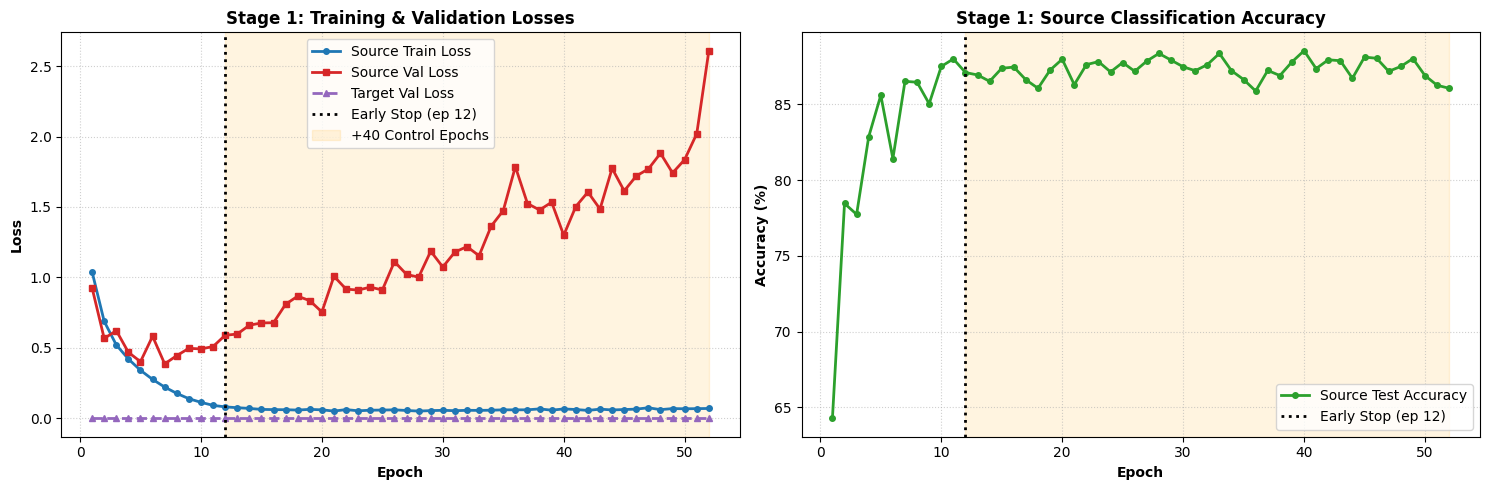

Stage 1 training curves saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage1_curves_20261112_190236.png


/tmp/ipykernel_5831/50371449.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab10', len(layer_names))


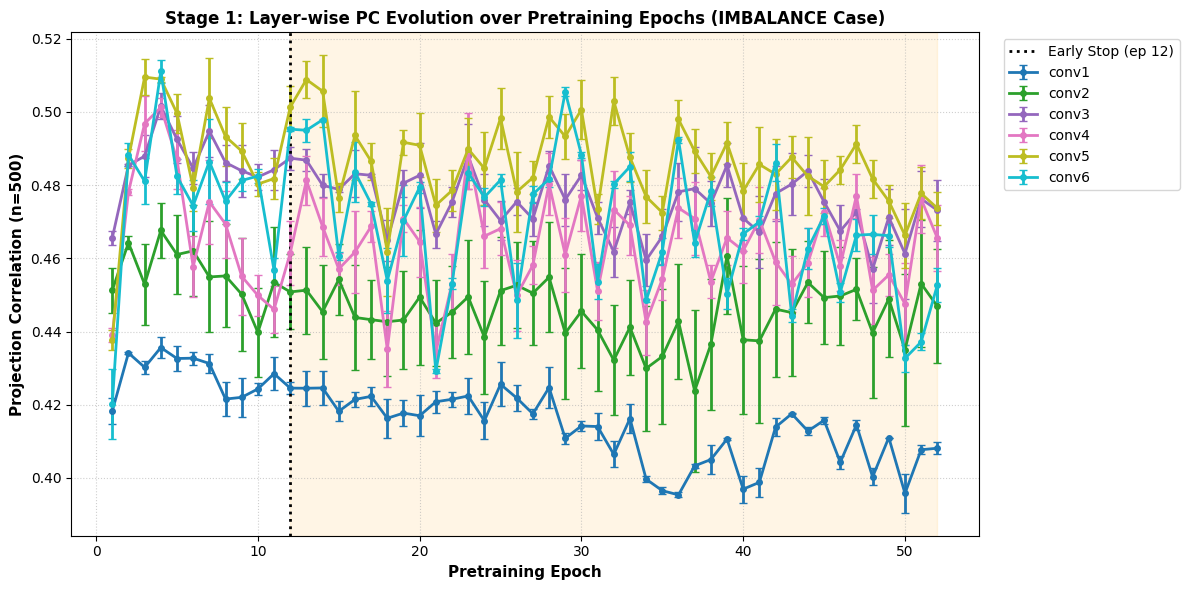

Stage 1 PC evolution plot saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage1_pc_evolution_20261112_190236.png


In [11]:
epochs_arr = [h['epoch'] for h in stage1_history]
tr_loss_arr = [h['train_loss'] for h in stage1_history]
s_val_loss_arr = [h['source_val_loss'] for h in stage1_history]
t_val_loss_arr = [h['target_val_loss'] for h in stage1_history]
s_acc_arr = [h['source_test_acc'] for h in stage1_history]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Losses
axes[0].plot(epochs_arr, tr_loss_arr, 'o-', color='#1f77b4', label='Source Train Loss', linewidth=2, markersize=4)
axes[0].plot(epochs_arr, s_val_loss_arr, 's-', color='#d62728', label='Source Val Loss', linewidth=2, markersize=4)
axes[0].plot(epochs_arr, t_val_loss_arr, '^--', color='#9467bd', label='Target Val Loss', linewidth=2, markersize=4)
if early_stop_epoch:
    axes[0].axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
    axes[0].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color='orange', label=f'+{POST_EARLY_STOP_EPOCHS} Control Epochs')
axes[0].set_xlabel('Epoch', fontweight='bold')
axes[0].set_ylabel('Loss', fontweight='bold')
axes[0].set_title('Stage 1: Training & Validation Losses', fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# Plot 2: Source Accuracy
axes[1].plot(epochs_arr, s_acc_arr, 'o-', color='#2ca02c', label='Source Test Accuracy', linewidth=2, markersize=4)
if early_stop_epoch:
    axes[1].axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
    axes[1].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color='orange')
axes[1].set_xlabel('Epoch', fontweight='bold')
axes[1].set_ylabel('Accuracy (%)', fontweight='bold')
axes[1].set_title('Stage 1: Source Classification Accuracy', fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
curves_path = make_result_path("stage1_curves", "png", stage1_ts)
plt.savefig(curves_path, dpi=150)
plt.show()
print(f"Stage 1 training curves saved to: {curves_path}")

# Plot 3: Projection Correlation Evolution per Layer
plt.figure(figsize=(12, 6))
layer_names = CIFAR6CNN.LAYER_NAMES
cmap = plt.cm.get_cmap('tab10', len(layer_names))

for l_idx, layer in enumerate(layer_names):
    means = [h['pc_profiles'][primary_sample_size][layer]['mean'] for h in stage1_history]
    stds = [h['pc_profiles'][primary_sample_size][layer]['std'] for h in stage1_history]
    plt.errorbar(
        epochs_arr, means, yerr=stds,
        fmt='o-', color=cmap(l_idx),
        linewidth=2, markersize=4, capsize=3,
        label=f'{layer}'
    )

if early_stop_epoch:
    plt.axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
    plt.axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.1, color='orange')

plt.xlabel('Pretraining Epoch', fontweight='bold', fontsize=11)
plt.ylabel(f'Projection Correlation (n={primary_sample_size})', fontweight='bold', fontsize=11)
plt.title(f'Stage 1: Layer-wise PC Evolution over Pretraining Epochs ({EXPERIMENT_CASE.upper()} Case)', fontweight='bold', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

pc_evolution_path = make_result_path("stage1_pc_evolution", "png", stage1_ts)
plt.savefig(pc_evolution_path, dpi=150)
plt.show()
print(f"Stage 1 PC evolution plot saved to: {pc_evolution_path}")


## 7. Stage 2: Target Fine-Tuning on Fixed SAMPLE_SIZES with Early Stopping (All 7 Cases: $M_0 \dots M_6$)
- Fine-tune all 7 candidate transferred models $M_k$ ($k \in \{0, 1, 2, 3, 4, 5, 6\}$) using the fixed `SAMPLE_SIZES` target training subset (`fixed_target_subsets[primary_sample_size][0]['loader']`):
  - **$M_0$ ($k=0$)**: 0 transferred layers (trained from scratch on target subset).
  - **$M_1 \dots M_5$ ($k=1..5$)**: First $k$ layers transferred from best Stage 1 source checkpoint, remaining $6-k$ layers initialized randomly.
  - **$M_6$ ($k=6$)**: All 6 convolutional layers transferred from best Stage 1 source checkpoint.
  - Target classifier is initialized randomly for `splits['num_target_classes']`.
  - All layers fine-tuned (`freeze_transferred=False`, `k_freeze=0`).
- Early stopping monitoring on the fixed `SAMPLE_SIZES` target training subset:
  - Evaluate loss and accuracy on the full target validation/test set (`target_test_loader`).
  - Monitored metric: **Target Validation Loss** (with early stopping patience = `TARGET_PATIENCE`).
- Logged each epoch:
  - `Epoch ep:02d/EPOCHS:02d`
  - `Train Loss: avg_loss:.4f`
  - `Test Acc: v_acc * 100:.1f%`
  - `Val Loss: val_loss:.4f`
  - `PC (conv1..conv6)` for all layers


In [12]:
print("=" * 75)print(f"[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)")print(f"Fixed sample size: n={primary_sample_size} | Early stopping patience: {TARGET_PATIENCE} | Max epochs: {TARGET_EPOCHS}")print("=" * 75)# Fixed target training loader (using the first replication of primary_sample_size)target_train_subset_loader = fixed_target_subsets[primary_sample_size][0]['loader']num_target_classes = splits['num_target_classes']target_criterion = nn.CrossEntropyLoss()stage2_results = {}stage2_ts = get_timestamp()for k in range(0, 7):    model_name = f"M_{k}"    print("\n" + "=" * 75)    print(f"[Stage 2] Model {model_name} (transferred k={k} layers from pre-trained source model)")    print(f"Fine-tuning on fixed target subset (n={primary_sample_size}), monitored metric: Target Validation Loss")    print("=" * 75)    # Load best checkpoint from Stage 1 into source_model before transferring layers    if best_source_state is not None:        source_model.load_state_dict(best_source_state)    target_model = create_transferred_model(        pretrained_model=source_model,        k=k,        num_target_classes=num_target_classes,        freeze_transferred=False    ).to(device)    set_trainable_layers(target_model, k_freeze=0)    target_optimizer = torch.optim.RMSprop(        target_model.parameters(),        lr=LEARNING_RATE_TARGET,        alpha=0.9    )    stage2_history_k = []    best_t_val_loss = float('inf')    best_t_val_acc = 0.0    best_target_state = None    target_patience_counter = 0    target_early_stop_epoch = None    for ep in range(1, TARGET_EPOCHS + 1):        target_model.train()        tr_loss = 0.0        for x, y in target_train_subset_loader:            x, y = x.to(device), y.to(device)            target_optimizer.zero_grad()            out = target_model(x)            loss = target_criterion(out, y)            loss.backward()            target_optimizer.step()            tr_loss += loss.item() * x.size(0)        avg_train_loss = tr_loss / len(target_train_subset_loader.dataset)        # Evaluate loss and accuracy on full target validation/test set        val_loss, test_acc = default_eval_loss(target_model, target_test_loader, target_criterion, device)        # Compute PC on fixed subsets during fine-tuning        try:            pc_stats = evaluate_layer_pc_profiles(                target_model, fixed_target_subsets, device=device,                one_hot=True, num_classes=num_target_classes            )        except TypeError:            pc_stats = evaluate_layer_pc_profiles(target_model, fixed_target_subsets, device=device)        pc_str = format_pc_summary(pc_stats, ipc_stats, target_size=primary_sample_size)        # Logged each epoch:        print(f"[{model_name}] Epoch {ep:02d}/{TARGET_EPOCHS:02d} | "              f"Train Loss: {avg_train_loss:.4f} | "              f"Test Acc: {test_acc * 100:.1f}% | "              f"Val Loss: {val_loss:.4f} | "              f"PC: {pc_str}")        stage2_history_k.append({            'epoch': ep,            'train_loss': float(avg_train_loss),            'val_loss': float(val_loss),            'test_acc': float(test_acc * 100.0),            'pc_profiles': pc_stats        })        # Early stopping check on Target Validation Loss        if val_loss < best_t_val_loss:            best_t_val_loss = val_loss            best_t_val_acc = test_acc * 100.0            best_target_state = {key: val.cpu().clone() for key, val in target_model.state_dict().items()}            target_patience_counter = 0        else:            target_patience_counter += 1            if target_patience_counter >= TARGET_PATIENCE:                target_early_stop_epoch = ep                print(f"\n>>> [Target Early Stop] {model_name} triggered at epoch {ep} (Patience={TARGET_PATIENCE}). Stopping Stage 2 for {model_name}.\n")                break    # Save individual model checkpoint    ft_model_path = make_result_path(f"finetuned_model_{model_name}", "pt", stage2_ts)    torch.save({        'k': k,        'model_name': model_name,        'best_state_dict': best_target_state,        'final_state_dict': target_model.state_dict(),        'best_val_loss': best_t_val_loss,        'best_test_acc': best_t_val_acc,        'early_stop_epoch': target_early_stop_epoch    }, ft_model_path)    print(f"[{model_name}] Checkpoint saved to: {ft_model_path}")    stage2_results[k] = {        'k': k,        'model_name': model_name,        'transferred_layers': k,        'best_val_loss': float(best_t_val_loss),        'best_test_acc': float(best_t_val_acc),        'early_stop_epoch': target_early_stop_epoch,        'total_epochs': len(stage2_history_k),        'history': stage2_history_k,        'checkpoint_path': ft_model_path    }# Backward compatibility aliasbest_k_idx = min(stage2_results.keys(), key=lambda k: stage2_results[k]['best_val_loss'])stage2_history = stage2_results[best_k_idx]['history']target_early_stop_epoch = stage2_results[best_k_idx]['early_stop_epoch']# Save complete Stage 2 results across all 7 casesstage2_history_path = make_result_path("stage2_history_all_cases", "json", stage2_ts)with open(stage2_history_path, 'w', encoding='utf-8') as f:    json.dump({        'stage': 'stage2_fine_tuning_all_cases',        'experiment_case': EXPERIMENT_CASE,        'target_sample_size': primary_sample_size,        'target_patience': TARGET_PATIENCE,        'target_epochs': TARGET_EPOCHS,        'models': {            f"M_{k}": {                'k': res['k'],                'best_val_loss': res['best_val_loss'],                'best_test_acc': res['best_test_acc'],                'early_stop_epoch': res['early_stop_epoch'],                'total_epochs': res['total_epochs'],                'history': res['history']            } for k, res in stage2_results.items()        }    }, f, indent=2)print("\n" + "=" * 75)print(f"Stage 2 (All 7 Cases) completed successfully!")print(f"Metrics saved to: {stage2_history_path}")print("=" * 75)# Summary table of all 7 casesprint(f"{'Model':<8} | {'Transferred (k)':<16} | {'Best Val Loss':<14} | {'Best Test Acc (%)':<18} | {'Early Stop Epoch':<16}")print("-" * 80)for k in range(0, 7):    res = stage2_results[k]    es_str = f"Epoch {res['early_stop_epoch']}" if res['early_stop_epoch'] else f"Max ({res['total_epochs']})"    print(f"{res['model_name']:<8} | {res['transferred_layers']:<16} | {res['best_val_loss']:<14.4f} | {res['best_test_acc']:<18.2f} | {es_str:<16}")print("-" * 80)print(f"Optimal Model across all 7 cases: M_{best_k_idx} (k* = {best_k_idx}) with Val Loss = {stage2_results[best_k_idx]['best_val_loss']:.4f}")print("=" * 75)

[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)
Fixed sample size: n=500 | Early stopping patience: 5 | Max epochs: 50

[Stage 2] Model M_0 (transferred k=0 layers from pre-trained source model)
Fine-tuning on fixed target subset (n=500), monitored metric: Target Validation Loss
[M_0] Epoch 01/50 | Train Loss: 1.6378 | Test Acc: 20.4% | Val Loss: 1.6089 | PC: conv1=0.275±0.021 | conv2=0.279±0.020 | conv3=0.269±0.020 | conv4=0.248±0.017 | conv5=0.223±0.015 | conv6=0.200±0.015
[M_0] Epoch 02/50 | Train Loss: 1.6072 | Test Acc: 26.6% | Val Loss: 1.5827 | PC: conv1=0.287±0.019 | conv2=0.360±0.005 | conv3=0.400±0.003 | conv4=0.398±0.000 | conv5=0.397±0.000 | conv6=0.394±0.000
[M_0] Epoch 03/50 | Train Loss: 1.6989 | Test Acc: 37.0% | Val Loss: 1.4593 | PC: conv1=0.312±0.016 | conv2=0.406±0.005 | conv3=0.412±0.007 | conv4=0.397±0.008 | conv5=0.392±0.007 | conv6=0.392±0.008
[M_0] Epoch 04/50 | Train Loss: 1.4113 | Test Acc: 36.5% | Val Loss: 1.3898 | PC: conv1

## 8. Stage 2 Visualizations: Fine-Tuning Curves & PC Trajectories (All 7 Cases)1. **Comparative Fine-Tuning Curves**:   - Target Validation Loss vs Epoch across all 7 models ($M_0 \dots M_6$).   - Target Test Accuracy (%) vs Epoch across all 7 models ($M_0 \dots M_6$).   - Performance (Best Validation Loss and Best Test Accuracy) vs Number of Transferred Layers ($k$).2. **Individual Fine-Tuning Curves (Grid of all 7 cases)**:   - Per-model Loss curves (Train vs Val) and Accuracy curve with Early Stopping lines.3. **Layer-wise PC and IPC Trajectories for all 7 cases**:   - Evolution of Projection Correlation (PC) and Improved Projection Correlation (IPC) for all layers (`conv1`..`conv6`) during target fine-tuning for each model.   - Evolution of Projection Correlation for all layers (`conv1`..`conv6`) during target fine-tuning for each model.4. **Final PC Profile Comparison across Models**:   - Layer generality comparison across $M_0 \dots M_6$.

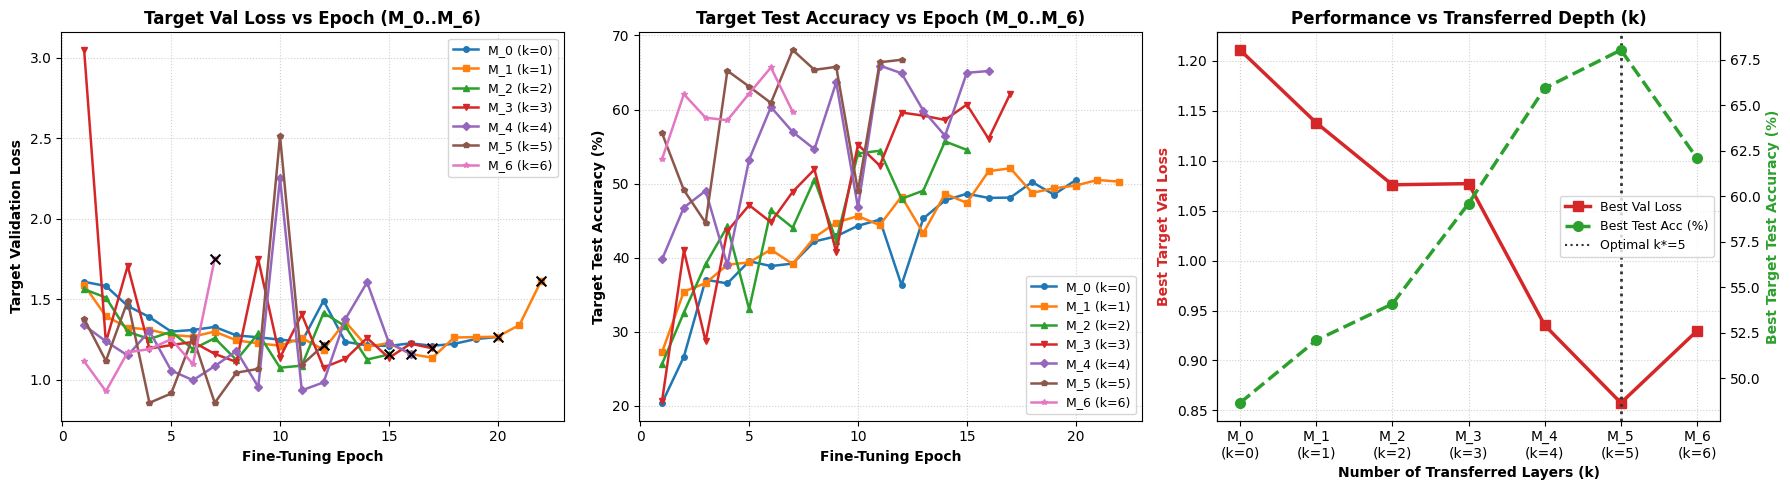

Stage 2 comparative curves saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage2_curves_comparison_20261112_190238.png


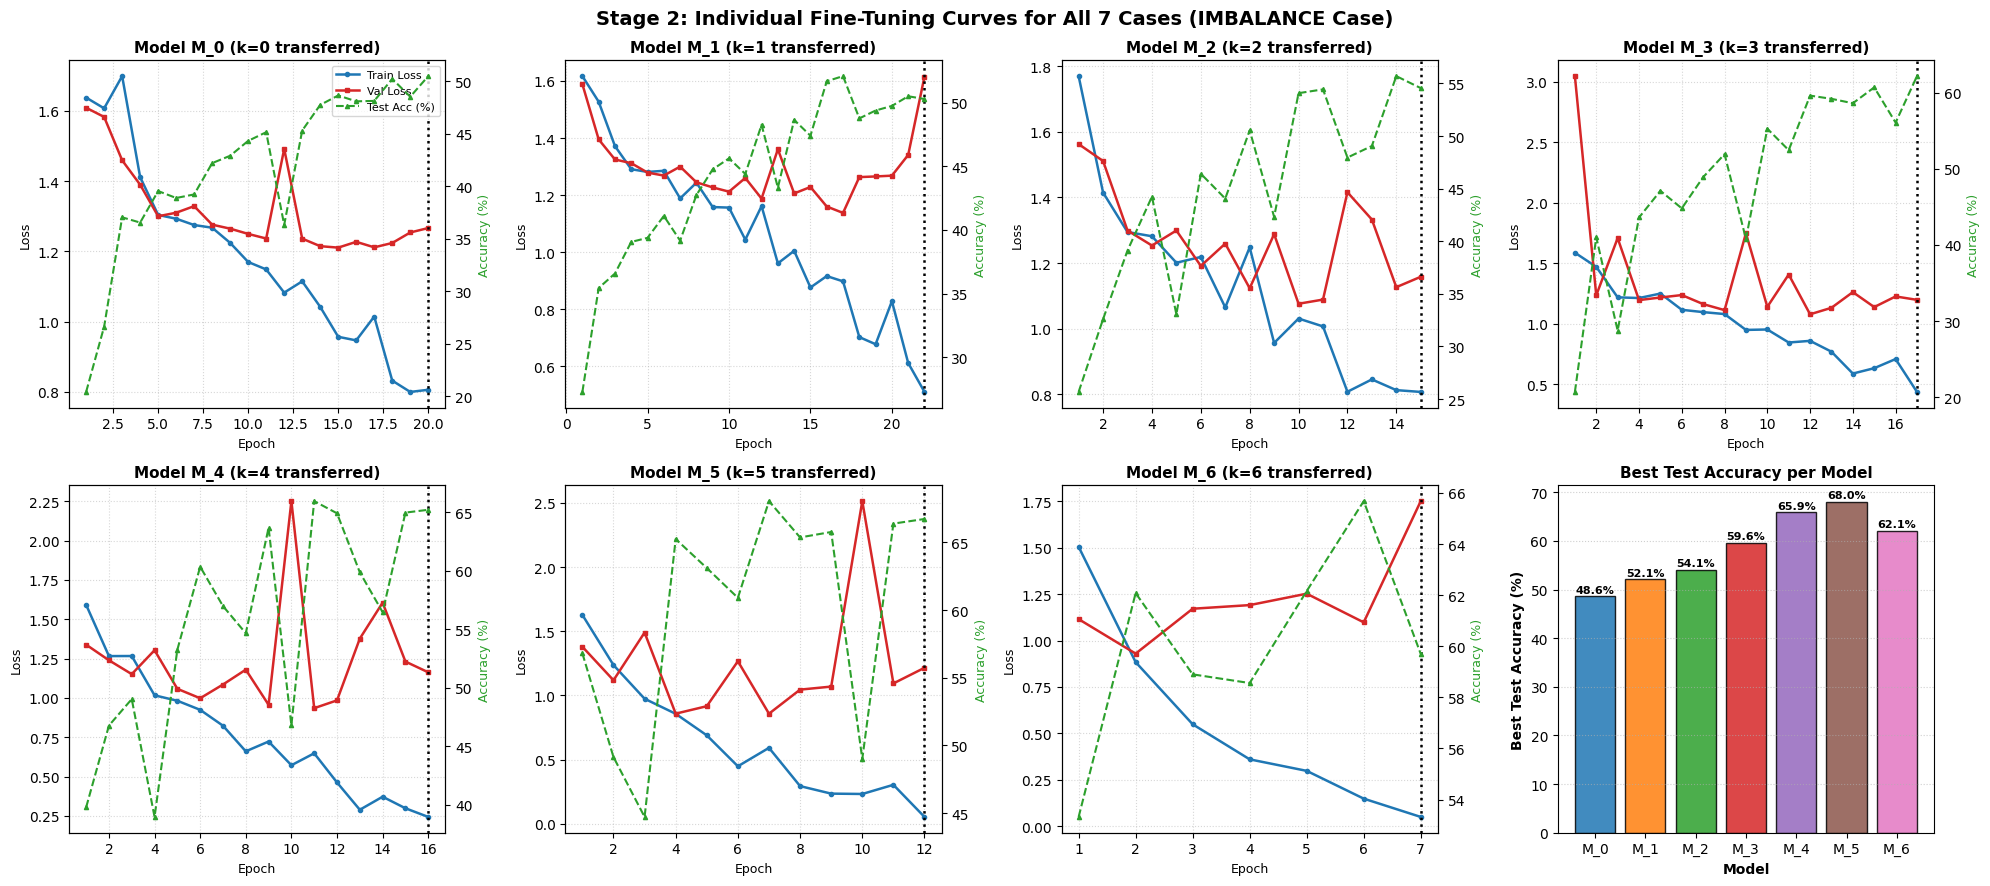

Stage 2 individual curves saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage2_curves_all_7_cases_20261112_190238.png


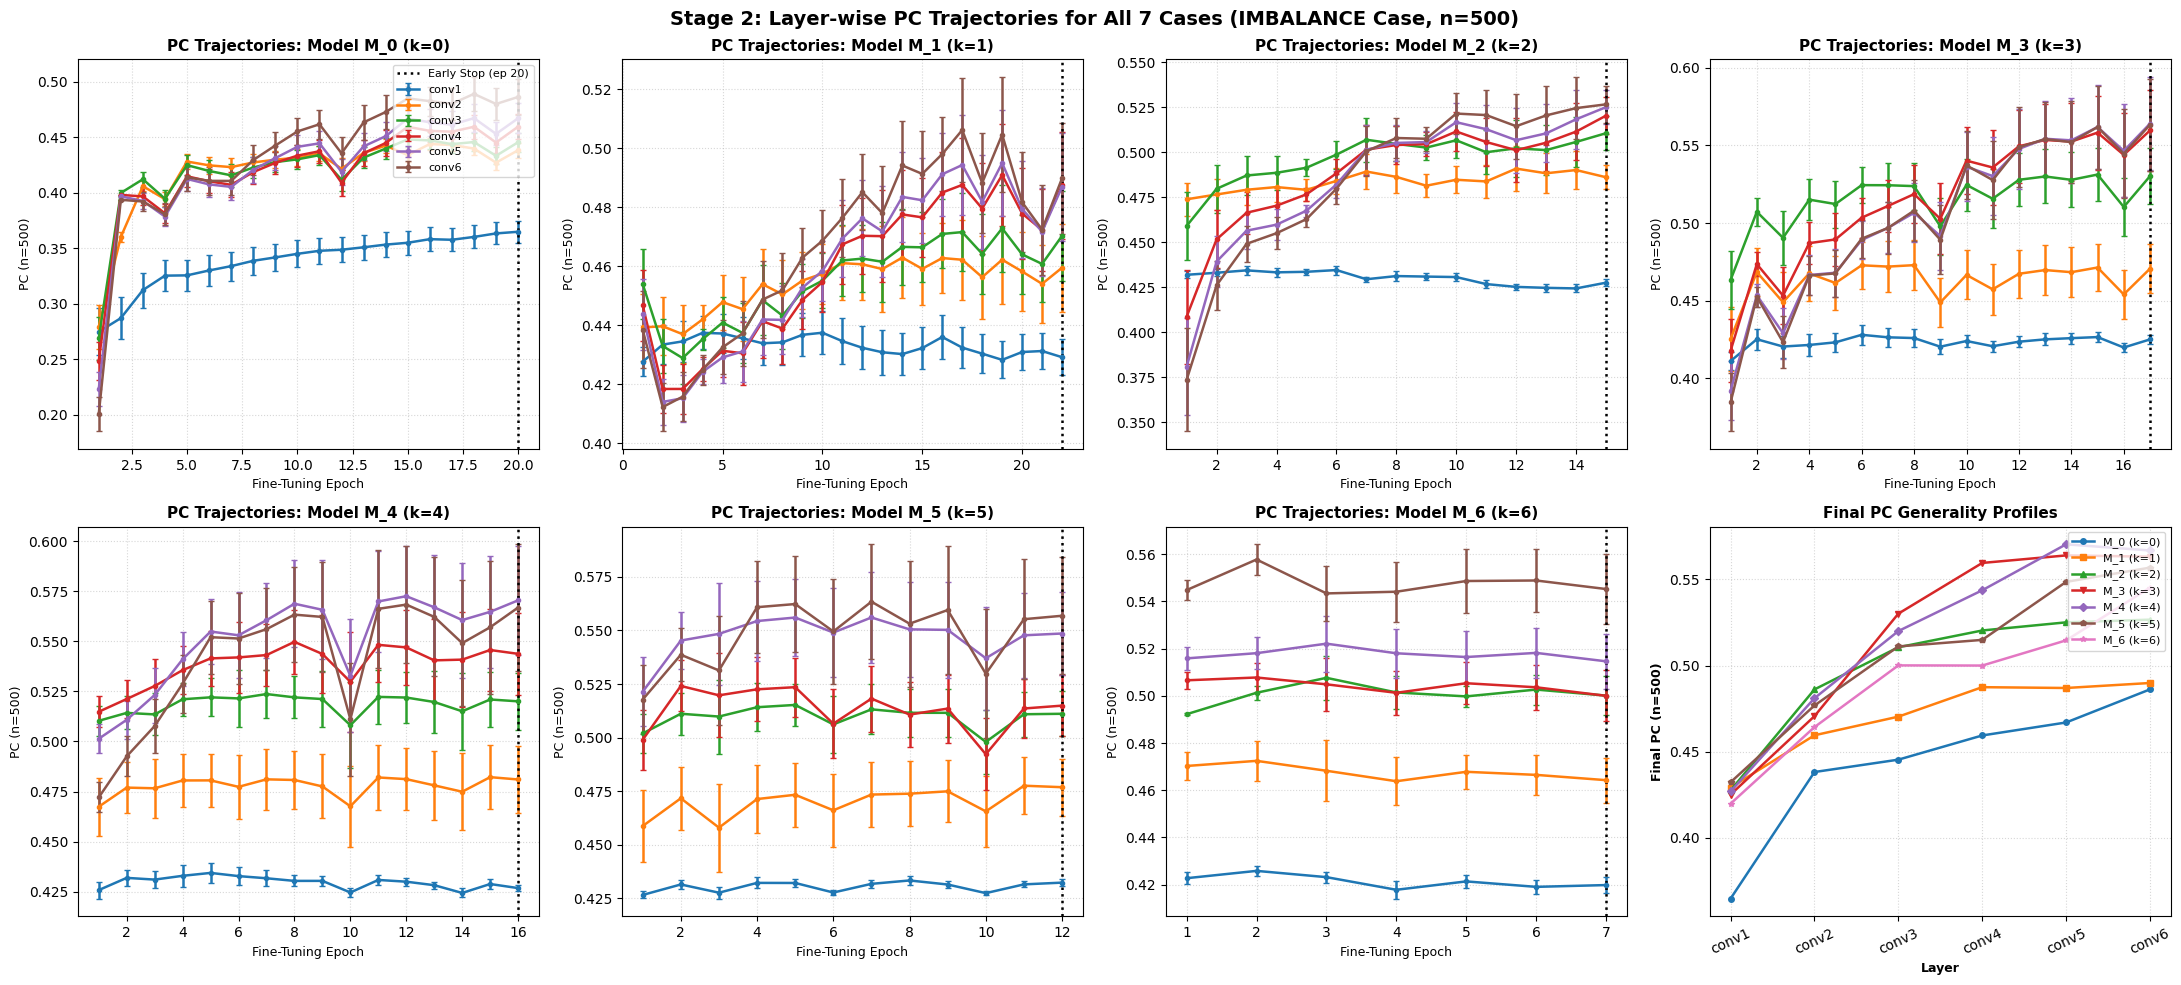

Stage 2 PC trajectories for all 7 cases saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage2_pc_trajectories_all_7_cases_20261112_190238.png


In [13]:
# Shared styling configurationmodel_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']model_markers = ['o', 's', '^', 'v', 'D', 'p', '*']ks = list(range(0, 7))layer_names = CIFAR6CNN.LAYER_NAMEStry:    cmap = plt.colormaps['tab10']except (AttributeError, KeyError):    cmap = plt.cm.get_cmap('tab10')# =========================================================================# Figure 1: Comparative Curves across All 7 Cases (M_0 ... M_6)# =========================================================================fig, axes = plt.subplots(1, 3, figsize=(18, 5))# Subplot 1A: Target Validation Loss vs Epochfor k in ks:    hist_k = stage2_results[k]['history']    eps = [h['epoch'] for h in hist_k]    v_loss = [h['val_loss'] for h in hist_k]    es = stage2_results[k]['early_stop_epoch']    axes[0].plot(eps, v_loss, marker=model_markers[k], color=model_colors[k],                 linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")    if es and es <= len(v_loss):        axes[0].scatter([es], [v_loss[es-1]], color='black', s=50, zorder=5, marker='x')axes[0].set_xlabel('Fine-Tuning Epoch', fontweight='bold')axes[0].set_ylabel('Target Validation Loss', fontweight='bold')axes[0].set_title('Target Val Loss vs Epoch (M_0..M_6)', fontweight='bold')axes[0].grid(True, linestyle=':', alpha=0.6)axes[0].legend(fontsize=9, loc='upper right')# Subplot 1B: Target Test Accuracy vs Epochfor k in ks:    hist_k = stage2_results[k]['history']    eps = [h['epoch'] for h in hist_k]    t_acc = [h['test_acc'] for h in hist_k]    axes[1].plot(eps, t_acc, marker=model_markers[k], color=model_colors[k],                 linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")axes[1].set_xlabel('Fine-Tuning Epoch', fontweight='bold')axes[1].set_ylabel('Target Test Accuracy (%)', fontweight='bold')axes[1].set_title('Target Test Accuracy vs Epoch (M_0..M_6)', fontweight='bold')axes[1].grid(True, linestyle=':', alpha=0.6)axes[1].legend(fontsize=9, loc='lower right')# Subplot 1C: Performance vs Transferred Depth (k)best_losses = [stage2_results[k]['best_val_loss'] for k in ks]best_accs = [stage2_results[k]['best_test_acc'] for k in ks]best_k_loss = min(ks, key=lambda k: best_losses[k])ax_loss = axes[2]ax_acc = ax_loss.twinx()line1 = ax_loss.plot(ks, best_losses, 's-', color='#d62728', linewidth=2.5, markersize=7, label='Best Val Loss')line2 = ax_acc.plot(ks, best_accs, 'o--', color='#2ca02c', linewidth=2.5, markersize=7, label='Best Test Acc (%)')ax_loss.axvline(best_k_loss, color='#333333', linestyle=':', linewidth=2, label=f'Optimal k*={best_k_loss}')ax_loss.set_xlabel('Number of Transferred Layers (k)', fontweight='bold')ax_loss.set_ylabel('Best Target Val Loss', color='#d62728', fontweight='bold')ax_acc.set_ylabel('Best Target Test Accuracy (%)', color='#2ca02c', fontweight='bold')ax_loss.set_title('Performance vs Transferred Depth (k)', fontweight='bold')ax_loss.set_xticks(ks)ax_loss.set_xticklabels([f"M_{k}\n(k={k})" for k in ks])ax_loss.grid(True, linestyle=':', alpha=0.6)lines = line1 + line2 + [plt.Line2D([0], [0], color='#333333', linestyle=':', label=f'Optimal k*={best_k_loss}')]labels = [l.get_label() for l in lines]ax_loss.legend(lines, labels, loc='center right', fontsize=9)# Subplot 1D: Layer-wise PC vs IPC comparison (final profile, conv1 only)for k in ks:    hist_k = stage2_results[k]['history']    pc_final = []    ipc_final = []    for h in hist_k:        if h['pc_profiles'] and primary_sample_size in h['pc_profiles']:            last_profile = h['pc_profiles'][primary_sample_size]            pc_final.append(last_profile.get('conv1', {}).get('mean', None))            ipc_final.append(last_profile.get('conv1', {}).get('ipc_mean', None))    if pc_final:        axes[3].plot(range(1, len(pc_final)+1), pc_final, marker=model_markers[k], color=model_colors[k],                     linewidth=2, markersize=6, label=f"M_{k} - PC (conv1)", linewidth=1.5)        axes[3].plot(range(1, len(ipc_final)+1), ipc_final, marker=model_markers[k], color=model_colors[k],                     linewidth=1.5, markersize=5, linestyle=':', label=f"M_{k} - IPC (conv1)", alpha=0.4)axes[3].set_xlabel('Number of Transferred Layers (k)', fontweight='bold')axes[3].set_ylabel('Projection Correlation Value', fontweight='bold')axes[3].set_title('Final PC (solid) vs IPC (dashed) per Model', fontweight='bold')axes[3].grid(True, linestyle=':', alpha=0.6)axes[3].legend(fontsize=8, loc='upper right')plt.tight_layout()ft_comp_path = make_result_path("stage2_curves_comparison", "png", stage2_ts)plt.savefig(ft_comp_path, dpi=150)plt.show()print(f"Stage 2 comparative curves saved to: {ft_comp_path}")# =========================================================================# Figure 2: Individual Fine-Tuning Curves for Each of the 7 Cases# =========================================================================fig, axes = plt.subplots(2, 4, figsize=(20, 9))axes_flat = axes.flatten()for k in ks:    ax = axes_flat[k]    hist_k = stage2_results[k]['history']    eps = [h['epoch'] for h in hist_k]    tr_loss = [h['train_loss'] for h in hist_k]    v_loss = [h['val_loss'] for h in hist_k]    t_acc = [h['test_acc'] for h in hist_k]    es = stage2_results[k]['early_stop_epoch']    ax2 = ax.twinx()    l1 = ax.plot(eps, tr_loss, 'o-', color='#1f77b4', linewidth=1.8, markersize=3, label='Train Loss')    l2 = ax.plot(eps, v_loss, 's-', color='#d62728', linewidth=1.8, markersize=3, label='Val Loss')    l3 = ax2.plot(eps, t_acc, '^--', color='#2ca02c', linewidth=1.5, markersize=3, label='Test Acc (%)')    if es:        ax.axvline(es, color='black', linestyle=':', linewidth=1.8, label=f'Early Stop (ep {es})')    ax.set_title(f"Model M_{k} (k={k} transferred)", fontweight='bold', fontsize=11)    ax.set_xlabel('Epoch', fontsize=9)    ax.set_ylabel('Loss', fontsize=9)    ax2.set_ylabel('Accuracy (%)', color='#2ca02c', fontsize=9)    ax.grid(True, linestyle=':', alpha=0.5)    if k == 0:        lines_all = l1 + l2 + l3        labels_all = [l.get_label() for l in lines_all]        ax.legend(lines_all, labels_all, loc='upper right', fontsize=8)# 8th subplot: Summary Bar Chartax_sum = axes_flat[7]bars = ax_sum.bar(ks, best_accs, color=model_colors, edgecolor='black', alpha=0.85)ax_sum.set_xticks(ks)ax_sum.set_xticklabels([f"M_{k}" for k in ks])ax_sum.set_xlabel('Model', fontweight='bold')ax_sum.set_ylabel('Best Test Accuracy (%)', fontweight='bold')ax_sum.set_title('Best Test Accuracy per Model', fontweight='bold', fontsize=11)ax_sum.grid(True, axis='y', linestyle=':', alpha=0.6)for bar, acc in zip(bars, best_accs):    ax_sum.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, f"{acc:.1f}%",                ha='center', va='bottom', fontsize=8, fontweight='bold')plt.suptitle(f"Stage 2: Individual Fine-Tuning Curves for All 7 Cases ({EXPERIMENT_CASE.upper()} Case)", fontsize=14, fontweight='bold')plt.tight_layout()ft_indiv_path = make_result_path("stage2_curves_all_7_cases", "png", stage2_ts)plt.savefig(ft_indiv_path, dpi=150)plt.show()print(f"Stage 2 individual curves saved to: {ft_indiv_path}")# =========================================================================# Figure 3: Layer-wise PC Trajectories for All 7 Cases (M_0 ... M_6)# =========================================================================fig, axes = plt.subplots(2, 4, figsize=(22, 10))axes_flat = axes.flatten()for k in ks:    ax = axes_flat[k]    hist_k = stage2_results[k]['history']    eps = [h['epoch'] for h in hist_k]    es = stage2_results[k]['early_stop_epoch']    for l_idx, layer in enumerate(layer_names):        means = [h['pc_profiles'][primary_sample_size][layer]['mean'] for h in hist_k]        stds = [h['pc_profiles'][primary_sample_size][layer]['std'] for h in hist_k]        ax.errorbar(            eps, means, yerr=stds,            fmt='o-', color=cmap(l_idx),            linewidth=1.8, markersize=3, capsize=2,            label=f"{layer}"        )    if es:        ax.axvline(es, color='black', linestyle=':', linewidth=1.8, label=f'Early Stop (ep {es})')    ax.set_title(f"PC Trajectories: Model M_{k} (k={k})", fontweight='bold', fontsize=11)    ax.set_xlabel('Fine-Tuning Epoch', fontsize=9)    ax.set_ylabel(f'PC (n={primary_sample_size})', fontsize=9)    ax.grid(True, linestyle=':', alpha=0.5)# 8th subplot: Final PC generality profiles across all 7 modelsax_pc_comp = axes_flat[7]for k in ks:    hist_k = stage2_results[k]['history']    last_profile = hist_k[-1]['pc_profiles'][primary_sample_size]    final_means = [last_profile[l]['mean'] for l in layer_names]    ax_pc_comp.plot(range(1, 7), final_means, marker=model_markers[k], color=model_colors[k],                    linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")ax_pc_comp.set_xticks(range(1, 7))ax_pc_comp.set_xticklabels(layer_names, rotation=25)ax_pc_comp.set_xlabel('Layer', fontweight='bold', fontsize=9)ax_pc_comp.set_ylabel(f'Final PC (n={primary_sample_size})', fontweight='bold', fontsize=9)ax_pc_comp.set_title('Final PC Generality Profiles', fontweight='bold', fontsize=11)ax_pc_comp.grid(True, linestyle=':', alpha=0.5)ax_pc_comp.legend(fontsize=8, loc='upper right')axes_flat[0].legend(loc='upper right', fontsize=8)plt.suptitle(f"Stage 2: Layer-wise PC Trajectories for All 7 Cases ({EXPERIMENT_CASE.upper()} Case, n={primary_sample_size})",             fontsize=14, fontweight='bold')plt.tight_layout()ft_pc_path = make_result_path("stage2_pc_trajectories_all_7_cases", "png", stage2_ts)plt.savefig(ft_pc_path, dpi=150)plt.show()print(f"Stage 2 PC trajectories for all 7 cases saved to: {ft_pc_path}")

## 9. Experiment Summary and Saved Artifacts Inventory

In [14]:
print("=" * 75)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print(f"Results stored in catalog matching notebook name: '{RESULTS_DIR}'")
print("=" * 75)

artifacts = sorted(glob.glob(os.path.join(RESULTS_DIR, "*")))
print(f"Found {len(artifacts)} saved artifacts in '{RESULTS_DIR}':")
for art in artifacts:
    size_kb = os.path.getsize(art) / 1024.0
    print(f"  - {os.path.basename(art)} ({size_kb:.1f} KB)")
print("=" * 75)


EXPERIMENT COMPLETED SUCCESSFULLY
Results stored in catalog matching notebook name: '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained'
Found 85 saved artifacts in '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained':
  - finetuned_model_20261102_144935.pt (3457.7 KB)
  - finetuned_model_20261110_124540.pt (3459.8 KB)
  - finetuned_model_20261110_130306.pt (3459.8 KB)
  - finetuned_model_M_0_20261110_134915.pt (3460.1 KB)
  - finetuned_model_M_0_20261110_153023.pt (3460.1 KB)
  - finetuned_model_M_0_20261112_190238.pt (3460.1 KB)
  - finetuned_model_M_1_20261110_134915.pt (3460.1 KB)
  - finetuned_model_M_1_20261110_153023.pt (3460.1 KB)
  - finetuned_model_M_1_20261112_190238.pt (3460.1 KB)
  - finetuned_model_M_2_20261110_134915.pt (3460.1 KB)
  - finetuned_model_M_2_20261110_153023.pt (3460.1 KB)
  - finetuned_model_M_2_20261112_190238.pt (3460.1 KB)
  - finetuned_model_M_3_20261110_134915.pt (3460.1 KB)
  - finetuned_model_M_3_20261110_153023.pt (34